# Figure 1: cell-state composition of Dnmt mutant embryos and chimeras

Draws the per-embryo cell-state compositions and lineage-frequency violins of Fig. 1, plus related Extended Data panels.

Paper: Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **1a, 1b, 1e**: schematics and embryo images, no code (section: Fig. 1a, b, e)
- **1c**: cell-state composition, 4N mutants (section: Cell-state compositions)
- **1d**: lineage frequencies, 4N mutants (section: Lineage frequencies)
- **1f**: cell-state composition, Dnmt-TKO and -DKO chimeras, KO cells only; host row has no producer here (section: Cell-state compositions)
- **1g**: lineage frequencies, chimeras, host vs mutant (section: Lineage frequencies)
- **1h**: cell-state composition, single-mutant chimeras, KO cells only (section: Cell-state compositions)
- **1i**: lineage-wise expression correlation (section: Lineage-wise correlation)
- **ED 2e**: ExE mesoderm frequency, 4N mutants (section: Lineage frequencies)
- **ED 3d**: ExE mesoderm frequency, chimeras (section: Lineage frequencies)
- **ED 3f**: lineage frequencies, single-mutant chimeras, host vs mutant (section: Lineage frequencies)

Inputs: original analysis directory, via the repo's `data` link. Outputs: `out_path()` (`paths.R`), into `git_test/`.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)

In [2]:
source(file.path(repo_dir, "scripts/Fig1_func.r"))

`load_cell_type_md()` (`scripts/Fig1_func.r`) loads:
- the WT atlas cell-type colours (plus early and late nascent mesoderm)
- the cell type to lineage table `data/ref/cell_type_ref.csv` (Blood removed)
- each embryo's dissection day (`data/ref/embryo_classification.csv`)

In [3]:
cell_type_md = load_cell_type_md()

## Fig. 1c, f, h: cell-state compositions

- **1c**: cell-state composition per embryo, 4N mutants
- **1f**: same, KO-derived cells of Dnmt-TKO and -DKO chimeras
- **1h**: same, single-mutant chimeras

`plot_mars_compositions()` runs `plot_composition()` on each MARS-seq metacell model:
- 4N: control, Dnmt-TKO, Dnmt-DKO
- KO cells of the Dnmt-TKO and -DKO chimeras
- KO cells of the single-mutant chimeras (Dnmt1, Uhrf1, Dnmt3a, Dnmt3b)
- the WT atlas

Method:
- Cell type = its metacell's MCProj projection on the WT atlas.
- Cell types missing from `cell_type_ref` (incl. Blood) are dropped; embryos with < 100 remaining cells are dropped.
- One column per embryo, stacked by cell type, coloured by lineage; a strip below shows the day (E7.5 light grey, E8.5 dark grey).

Notes:
- Embryo order key: `exe_meso + 0.01/early + 0.01` (in effect, the ExE mesoderm fraction).
- Host rows of 1f and 1h are not produced here.

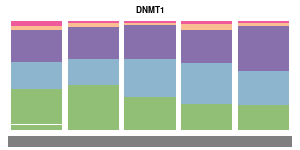

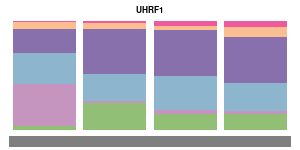

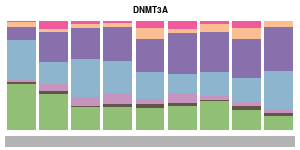

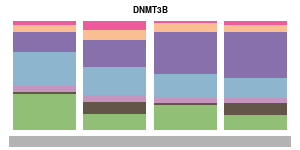

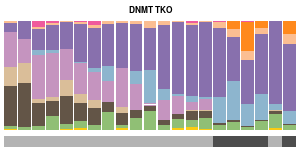

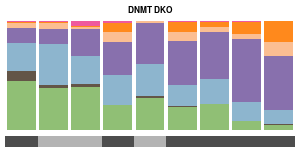

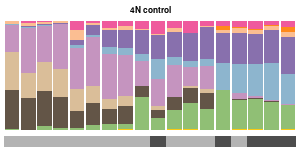

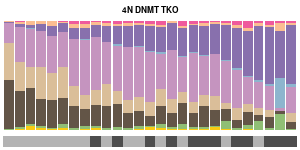

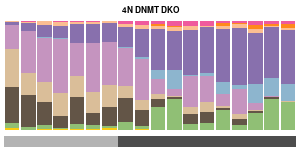

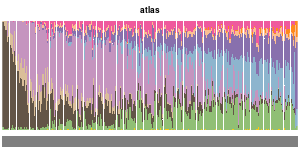

In [4]:
embryo_orders = plot_mars_compositions(cell_type_md)
saveRDS(embryo_orders, file = out_path("./data/output/embryo_orders.RDS"))

Writes, under `figs/Fig1/`:
- **1c**: `WT_4N_ff.pdf`, `DNMT_TKO_4N_ff.pdf`, `DNMT_DKO_4N_ff.pdf` (and `atlas.pdf` for the WT atlas)
- **1f** (KO cells): `DNMT_TKO_KO_ff.pdf`, `DNMT_DKO_KO_ff.pdf`
- **1h** (KO cells): `DNMT1_KO_ff.pdf`, `UHRF1_KO_ff.pdf`, `DNMT3A_KO_ff.pdf`, `DNMT3B_KO_ff.pdf`

Also writes:
- per-embryo counts: `data/output/composition/<model>.RDS`
- embryo orders: `data/output/embryo_orders.RDS`

## Fig. 1d, g and Extended Data Fig. 2e, 3d, 3f: lineage frequencies

- **1d**: lineage frequencies, 4N mutants vs control, E7.5 and E8.5
- **1g**: lineage frequencies, chimeras, host vs mutant cells
- **ED 2e**: ExE mesoderm frequency, 4N mutants
- **ED 3d**: ExE mesoderm frequency, Dnmt-TKO and -DKO chimeras
- **ED 3f**: lineage frequencies, host vs mutant

Method:
- `organize_lineage_stats()` (`scripts/Fig1_func.r`): per embryo, fraction of cells in Ectoderm, Endoderm, Embryonic mesoderm and ExE mesoderm.
- Reads composition tables from the original `data/output/composition/`, including host tables this repo can no longer regenerate.
- Violins: one per genotype and day; bars at median and median ± s.d.
- `produce_4N_violins()`: each 4N mutant vs 4N control, same day.
- `produce_2N_violins()`: chimera KO cells vs host cells, same day.
- Test: unpaired two-sided Wilcoxon rank-sum across embryos (\* p < 0.05, \*\* p < 0.01, \*\*\* p < 0.001).
- `plot_supp_violins()` (`produce_supp_violins()`): same for the single-mutant chimeras (KO vs host), E7.5 and E8.5 pooled.

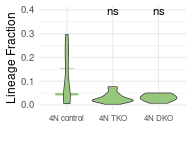

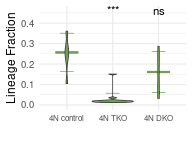

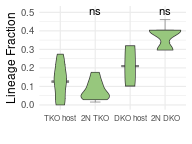

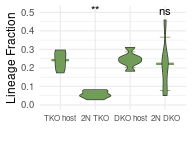

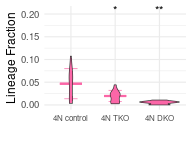

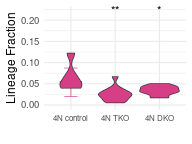

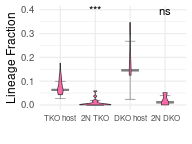

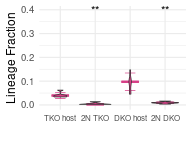

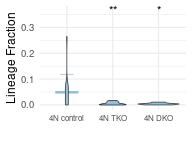

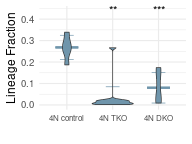

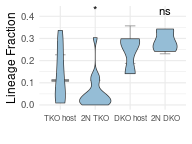

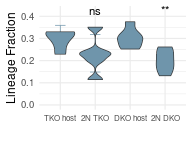

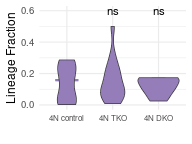

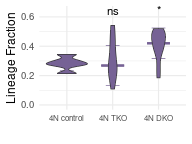

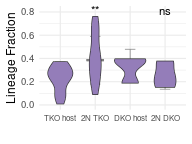

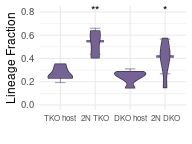

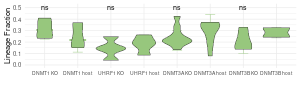

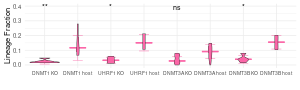

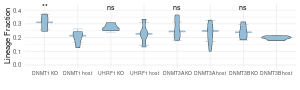

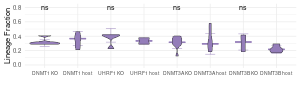

In [5]:
plot_all_violins()
plot_supp_violins()

Outputs:
- **1d**: `figs/Fig1/violins/<lineage>_<E7.5|E8.5>_4N.pdf` (ExE mesoderm files: **ED 2e**)
- **1g**: `figs/Fig1/violins/<lineage>_<E7.5|E8.5>_2N.pdf` (ExE mesoderm files: **ED 3d**)
- **ED 3f**: `figs/Supp/violins/<lineage>_E8.5_singles.pdf`

Notes:
- "E8.5" in the singles file names is a leftover; both days are pooled.

## Fig. 1a, b, e

- **1a**: schematic, 4N whole-embryo mutants
- **1b**: images of E7.5 and E8.5 Dnmt-DKO and -TKO whole-embryo mutants
- **1e**: schematic, 2N mixed chimeras

No code.

## Fig. 1i: lineage-wise correlation

- **1i**: correlation between lineage expression profiles, KO and host cells, across genotypes

`prep_single_cell()` (`scripts/single_cell_func.r`) loads the embryo-matched KO and host pseudo-bulk counts per genotype x lineage (`data/output/mko.RDS`, `mhost.RDS`; recomputed from `data/MC_models/RNA_all.h5ad` only if missing). See `prep/ko_vs_host.ipynb`.

For this panel (`sc$mko_lf`, `sc$mhost_lf`):
- each genotype x lineage column is downsampled to 250,000 UMIs (seeds 8056 for KO, 4958 for host: the original run's), then log2(2e-5 + frequency)
- only columns with ≥ 250,000 UMIs on both KO and host sides are kept
- each gene's median across columns is subtracted

In [6]:
source(file.path(repo_dir, "scripts/single_cell_func.r"))
sc <- prep_single_cell()

- KO and host profiles of all genotypes and lineages go in one matrix.
- Genes kept if > 1.5 above their median in at least one profile.
- Heatmap: Pearson correlation (`tgs_cor`), ordered by Ward clustering (`ward.D2`).
- Genotypes: Dnmt-TKO, Dnmt-DKO, Dnmt1, Dnmt3a, Dnmt3b, Uhrf1 chimeras.

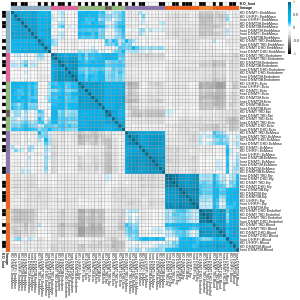

In [7]:
c_lf = cbind(sc$mko_lf, sc$mhost_lf)
colnames(c_lf)[1:ncol(sc$mko_lf)] = paste0("KO_", colnames(c_lf)[1:ncol(sc$mko_lf)])
colnames(c_lf)[(ncol(sc$mko_lf)+1):ncol(c_lf)] = paste0("host_", colnames(c_lf)[(ncol(sc$mko_lf)+1):ncol(c_lf)])                                                           
f = apply(cbind(sc$mko_lf, sc$mhost_lf),1,max)>1.5
auto = tgs_cor(c_lf[f,])
hc = hclust(tgs_dist(auto), "ward.D2")

rownames(auto) = fix_names(rownames(auto))
colnames(auto) = fix_names(colnames(auto))

phtmp_annot = data.frame(geno_layer = rownames(auto)) %>% mutate(layer = sapply(strsplit(geno_layer, "\\."), `[`, 2)) %>%
    mutate(layer = ifelse(layer == "Ery", "Blood", layer)) %>%
    left_join(sc$cell_type_ref)

annotation_dict = phtmp_annot %>% select(geno_layer, lineage) %>% mutate(KO_host = ifelse(grepl("host", geno_layer), "host", "KO")) %>% column_to_rownames("geno_layer")
annotation_colors = list("lineage" = phtmp_annot %>% pull(lineage_color, name = lineage),
                         "KO_host" = c("KO" = "black", "host" = "white"))

options(repr.plot.width = 12, repr.plot.height = 12)
show_fig("./figs/Fig1/lineage_wise_autocorrelation.pdf", draw = pheatmap::pheatmap(auto[hc$order,hc$order], 
                   cluster_rows = F, cluster_cols = F, 
                   annotation_col = annotation_dict, annotation_row = annotation_dict,
                   annotation_colors = annotation_colors,
                   annotation_legend = F,
                   width = 12, height = 12,
                   color = sc$colors, breaks = seq(-1, 1, length.out = 101)))

**1i**, written to `figs/Fig1/lineage_wise_autocorrelation.pdf` (no inline output).